!# Ordering temperatures from first-principles exchange
Fast estimates (mean field, RPA, quantum rescaling) and a short Monte Carlo run for monolayer CrI3, using the exchange bundled with magex.

In [1]:
import os, numpy as np, magex
from magex.spinmodel import load_results, SpinSystem, mean_field_tc
from magex.quantum import rpa_tc, quantum_rescale
root = os.path.join(os.path.dirname(magex.__file__), "..", "validation_runs")
uc = load_results(os.path.join(root, "CrI3_atomic_soc", "results.json.gz"))
T_rpa, T_mf = rpa_tc(uc)
print(f"T_MF = {T_mf:.1f} K, T_RPA = {T_rpa:.1f} K, quantum RPA = {quantum_rescale(T_rpa, uc.moments)[0]:.1f} K")

T_MF = 30.3 K, T_RPA = 24.9 K, quantum RPA = 41.0 K


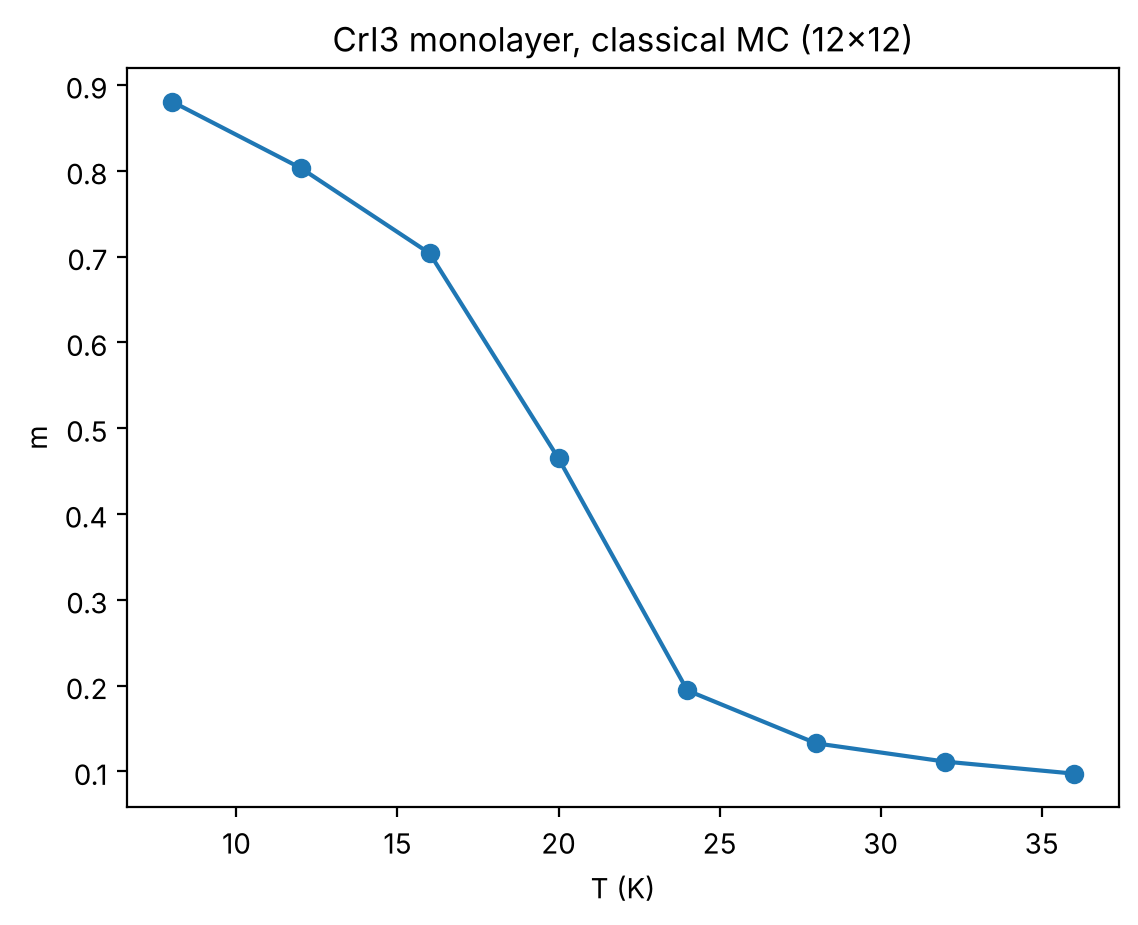

In [2]:
from magex.montecarlo import MetropolisMC
import matplotlib.pyplot as plt
sys = SpinSystem(uc, (12, 12, 1), (True, True, False))
Ts = np.linspace(8, 36, 8); ms = []
for T in Ts:
    mc = MetropolisMC(sys, T, seed=1); e = sys.init_spins("reference")
    for _ in range(300): e = mc.sweep(e)
    acc = []
    for _ in range(600):
        e = mc.sweep(e); acc.append(sys.order_parameter(e))
    ms.append(np.mean(acc))
plt.plot(Ts, ms, "o-"); plt.xlabel("T (K)"); plt.ylabel("m"); plt.title("CrI3 monolayer, classical MC (12x12)"); plt.show()